# Task 27: Logistic Regression from Scratch

## Objective
To implement Logistic Regression from scratch using gradient descent
without scikit-learn. Model performance will be evaluated using manually
calculated accuracy, precision, recall, and F1-score.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../../datasets/heart_final_cleaned.csv")

print("Dataset shape:", df.shape)
print(df.head())
print("\nTarget distribution:")
print(df["target"].value_counts())

Dataset shape: (302, 14)
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   52    1   0       125   212    0        1      168      0      1.0      2   
1   53    1   0       140   203    1        0      155      1      3.1      0   
2   70    1   0       145   174    0        1      125      1      2.6      0   
3   61    1   0       148   203    0        1      161      0      0.0      2   
4   62    0   0       138   294    1        1      106      0      1.9      1   

   ca  thal  target  
0   2     3       0  
1   0     3       0  
2   0     3       0  
3   1     3       0  
4   3     2       0  

Target distribution:
target
1    164
0    138
Name: count, dtype: int64


In [2]:
df = df.dropna().reset_index(drop=True)

X = df.drop(columns=["target"]).to_numpy(dtype=float)
y = df["target"].to_numpy(dtype=float)

classes = np.unique(y)

if len(classes) != 2:
    raise ValueError("This Logistic Regression implementation requires two target classes.")

# Convert target labels to 0 and 1
y = (y == classes[1]).astype(float)

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("Target classes mapped:", classes)

Feature shape: (302, 13)
Target shape: (302,)
Target classes mapped: [0. 1.]


In [3]:
def manual_stratified_split(X, y, train_ratio=0.8, random_seed=42):
    rng = np.random.default_rng(random_seed)

    train_indices = []
    test_indices = []

    for target_value in np.unique(y):
        class_indices = np.where(y == target_value)[0].copy()
        rng.shuffle(class_indices)

        split_index = int(len(class_indices) * train_ratio)

        train_indices.extend(class_indices[:split_index])
        test_indices.extend(class_indices[split_index:])

    train_indices = np.array(train_indices)
    test_indices = np.array(test_indices)

    rng.shuffle(train_indices)
    rng.shuffle(test_indices)

    return (
        X[train_indices],
        X[test_indices],
        y[train_indices],
        y[test_indices]
    )


X_train, X_test, y_train, y_test = manual_stratified_split(X, y)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (241, 13)
Testing set: (61, 13)


In [4]:
means = np.mean(X_train, axis=0)
stds = np.std(X_train, axis=0)

# Avoid division by zero for constant features
stds[stds == 0] = 1

X_train_scaled = (X_train - means) / stds
X_test_scaled = (X_test - means) / stds

print("Feature scaling completed.")

Feature scaling completed.


## Logistic Regression and Gradient Descent

The sigmoid function converts a linear score into a probability:

sigmoid(z) = 1 / (1 + exp(-z))

The model parameters are updated using gradient descent to minimize
binary cross-entropy loss.

In [5]:
def sigmoid(z):
    # Clip values to avoid numerical overflow
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))


def train_logistic_regression(X, y, learning_rate=0.01, epochs=2000):
    n_samples, n_features = X.shape

    weights = np.zeros(n_features)
    bias = 0.0
    losses = []

    for epoch in range(epochs):
        # Forward pass
        linear_output = X @ weights + bias
        probabilities = sigmoid(linear_output)

        # Binary cross-entropy loss
        epsilon = 1e-10
        probabilities_safe = np.clip(
            probabilities, epsilon, 1 - epsilon
        )

        loss = -np.mean(
            y * np.log(probabilities_safe)
            + (1 - y) * np.log(1 - probabilities_safe)
        )

        losses.append(loss)

        # Gradients
        error = probabilities - y

        dw = (X.T @ error) / n_samples
        db = np.sum(error) / n_samples

        # Update parameters
        weights -= learning_rate * dw
        bias -= learning_rate * db

    return weights, bias, losses


weights, bias, losses = train_logistic_regression(
    X_train_scaled,
    y_train,
    learning_rate=0.01,
    epochs=2000
)

print("Training completed.")
print("Bias:", bias)
print("Weights:", weights)

Training completed.
Bias: 0.09333347322790013
Weights: [-0.06742985 -0.54705631  0.71721022 -0.21287467 -0.21048079 -0.02094633
  0.13469485  0.50921975 -0.35257975 -0.58014638  0.30766765 -0.84665215
 -0.67079983]


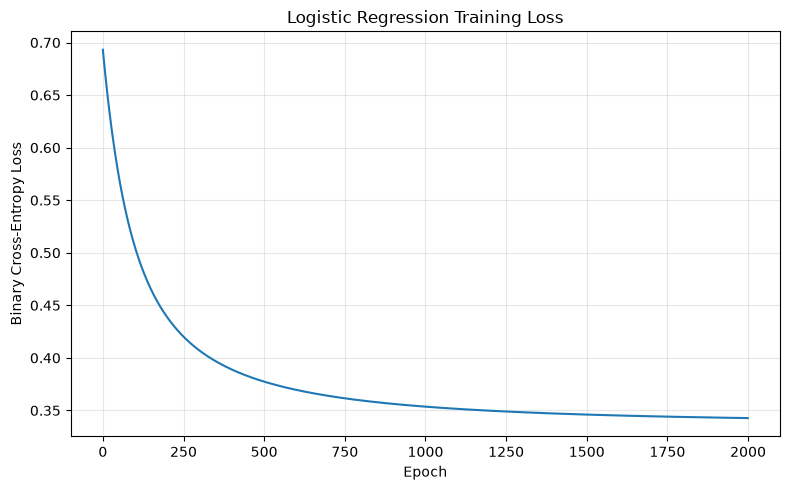

In [6]:
plt.figure(figsize=(8, 5))
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Logistic Regression Training Loss")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
test_probabilities = sigmoid(X_test_scaled @ weights + bias)

# Classification threshold = 0.5
y_pred = (test_probabilities >= 0.5).astype(int)

print("Actual labels:", y_test.astype(int))
print("Predicted labels:", y_pred)
print("Predicted probabilities:", np.round(test_probabilities, 3))

Actual labels: [0 1 0 1 0 0 1 1 1 1 0 0 1 1 1 0 0 0 0 1 0 0 1 0 1 1 0 0 0 1 1 1 1 0 1 1 0
 1 0 1 0 0 0 1 1 1 1 1 1 0 0 1 0 0 1 1 1 0 0 1 1]
Predicted labels: [1 1 1 1 0 1 1 1 1 1 1 0 1 1 1 0 0 0 0 1 0 0 0 1 1 1 0 0 0 1 0 1 0 0 1 1 0
 1 0 0 0 0 0 1 1 1 1 1 1 1 0 0 0 0 1 1 1 0 0 1 1]
Predicted probabilities: [0.696 0.935 0.877 0.589 0.43  0.593 0.716 0.89  0.943 0.949 0.505 0.122
 0.808 0.837 0.635 0.215 0.006 0.207 0.047 0.987 0.034 0.05  0.141 0.509
 0.994 0.97  0.033 0.002 0.056 0.881 0.382 0.754 0.388 0.155 0.547 0.951
 0.003 0.745 0.02  0.087 0.162 0.074 0.007 0.981 0.506 0.984 0.854 0.965
 0.812 0.879 0.008 0.066 0.27  0.004 0.947 0.714 0.748 0.109 0.049 0.915
 0.672]


In [8]:
def manual_metrics(y_true, y_pred):
    tp = 0
    tn = 0
    fp = 0
    fn = 0

    for actual, predicted in zip(y_true, y_pred):
        if actual == 1 and predicted == 1:
            tp += 1
        elif actual == 0 and predicted == 0:
            tn += 1
        elif actual == 0 and predicted == 1:
            fp += 1
        elif actual == 1 and predicted == 0:
            fn += 1

    accuracy = (tp + tn) / len(y_true) if len(y_true) else 0
    precision = tp / (tp + fp) if (tp + fp) else 0
    recall = tp / (tp + fn) if (tp + fn) else 0

    if precision + recall:
        f1 = 2 * precision * recall / (precision + recall)
    else:
        f1 = 0

    return {
        "TP": tp,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1
    }


metrics = manual_metrics(y_test.astype(int), y_pred)

print("Evaluation Results:")
for name, value in metrics.items():
    if isinstance(value, float):
        print(f"{name}: {value:.4f}")
    else:
        print(f"{name}: {value}")

Evaluation Results:
TP: 28
TN: 22
FP: 6
FN: 5
Accuracy: 0.8197
Precision: 0.8235
Recall: 0.8485
F1-score: 0.8358


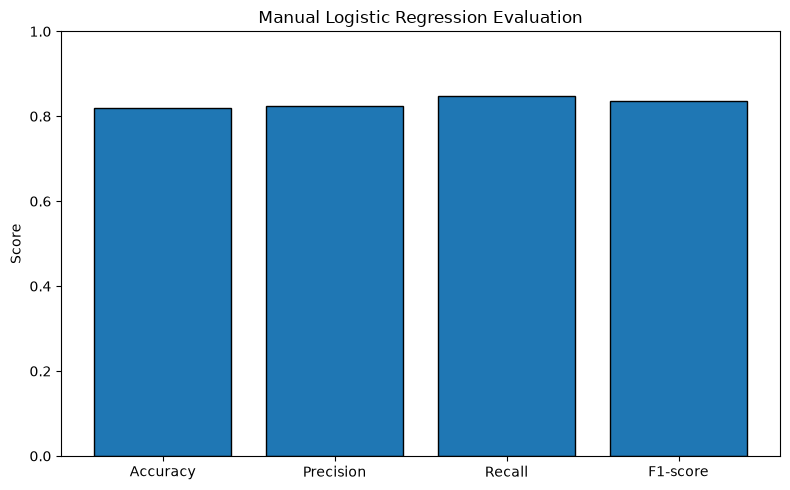

In [9]:
metric_names = ["Accuracy", "Precision", "Recall", "F1-score"]
metric_values = [metrics[name] for name in metric_names]

plt.figure(figsize=(8, 5))
plt.bar(
    metric_names,
    metric_values,
    edgecolor="black"
)

plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Manual Logistic Regression Evaluation")
plt.tight_layout()
plt.show()

## Conclusion

Logistic Regression was implemented from scratch using the sigmoid
function and gradient descent. Feature scaling was performed using
training data statistics, and model performance was evaluated using
manually calculated accuracy, precision, recall, and F1-score.

The results depend on the dataset, train-test split, learning rate,
number of epochs, and classification threshold. This educational model
is not intended for clinical diagnosis.